In [1]:
import torch
import matplotlib.pyplot as plt
import os
import time
import numpy as np
import random
from matplotlib.patches import Rectangle
import tifffile
import h5py
from torch.utils.data import DataLoader
import imageio.v2 as imageio
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Patch

import importlib as imp
import sys
sys.path.append(os.path.join(os.path.split(os.getcwd())[0], 'scripts'))

import yolo_tiles
imp.reload(yolo_tiles)
from yolo_tiles import img_to_tiles, apply_model_to_tiles, load_test_image, preprocess, tileDataset, remove_bbox_in_overlap

import yolo_help
imp.reload(yolo_help)
from yolo_help import bbox_to_rectangles, imshow, convert_data, Net, get_best_bounding_box_per_cell

import yolo_post_help
imp.reload(yolo_post_help)
from yolo_post_help import postprocess, bb_to_rec, NMS

import yolo_help_3D
imp.reload(yolo_help_3D)
from yolo_help_3D import apply_model_to_orthogonal_slices, gen_3D_GT, recon_down, vol_to_mip_rgb, orthogonal_to_3D, vol_to_mip

import yolo_avg_prec
imp.reload(yolo_avg_prec)
from yolo_avg_prec import get_AP, gt_bbox_to_pred_bbox_format, IOU_3D, yolo_output_to_list

import yolo_3D_pipeline_help
imp.reload(yolo_3D_pipeline_help)
from yolo_3D_pipeline_help import apply_2D_yolo_to_slices, stitch_slices_into_cube

import nibabel as nib

from csbdeep.utils import normalize

from matplotlib.colors import Normalize
from matplotlib import transforms

# NOTE: I used "pip install stardist cellpose" instead of cloning their GitHub repos this time
# sys.path.append('/ifshome/abenneck/docs_public/libraries/cellpose')
# from stardist.models import StarDist3D
# from cellpose import models

I0000 00:00:1791902632.287143  808086 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791902632.318813  808086 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791902633.182006  808086 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [28]:
# From an example in matplotlib's documentation (https://matplotlib.org/stable/gallery/mplot3d/imshow3d.html)
def imshow3d(ax, array, value_direction='z', pos=0, norm=None, cmap=None):
    """
    Display a 2D array as a  color-coded 2D image embedded in 3d.

    The image will be in a plane perpendicular to the coordinate axis *value_direction*.

    Parameters
    ----------
    ax : Axes3D
        The 3D Axes to plot into.
    array : 2D numpy array
        The image values.
    value_direction : {'x', 'y', 'z'}
        The axis normal to the image plane.
    pos : float
        The numeric value on the *value_direction* axis at which the image plane is
        located.
    norm : `~matplotlib.colors.Normalize`, default: Normalize
        The normalization method used to scale scalar data. See `imshow()`.
    cmap : str or `~matplotlib.colors.Colormap`, default: :rc:`image.cmap`
        The Colormap instance or registered colormap name used to map scalar data
        to colors.
    """
    if norm is None:
        norm = Normalize()
    colors = plt.get_cmap(cmap)(norm(array))

    if value_direction == 'x':
        nz, ny = array.shape
        zi, yi = np.mgrid[0:nz + 1, 0:ny + 1]
        xi = np.full_like(yi, pos)
    elif value_direction == 'y':
        nx, nz = array.shape
        xi, zi = np.mgrid[0:nx + 1, 0:nz + 1]
        yi = np.full_like(zi, pos)
    elif value_direction == 'z':
        ny, nx = array.shape
        yi, xi = np.mgrid[0:ny + 1, 0:nx + 1]
        zi = np.full_like(xi, pos)
    else:
        raise ValueError(f"Invalid value_direction: {value_direction!r}")
    ax.plot_surface(xi, yi, zi, rstride=1, cstride=1, facecolors=colors, shade=False)

# Figure 0 - Overview Fig

In [2]:
# Load the input volume

fname = '/home/abenneck/mounts/bmaproot/nafs/shattuck/RodentToolsData/Stacked/Ex_488_Em_525_stitched_chunk32.h5'
vol = h5py.File(fname)
vol_stack = vol['stack']

## (0.1) Original Input

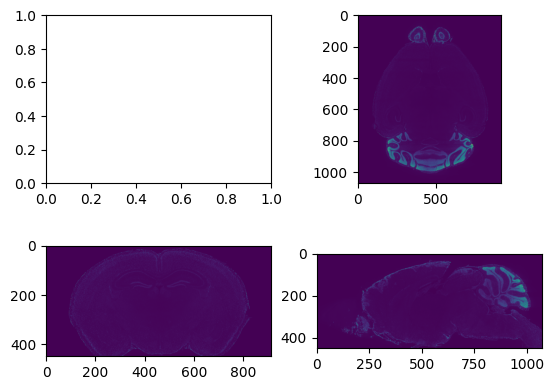

In [3]:
fig, ax = plt.subplots(2,2)

m0 = vol_stack.shape[0] // 2
m1 = vol_stack.shape[1] // 2
m2 = vol_stack.shape[2] // 2

img0 = vol_stack[m0, :, :]
img1 = vol_stack[:, m1, :]
img2 = vol_stack[:, :, m2]

ax[0,1].imshow(img0[::8,::8])
ax[1,0].imshow(img1[::8,::8])
ax[1,1].imshow(img2[::8,::8])



In [10]:
img0 = vol_stack[m0, :, :]
img1 = vol_stack[:, m1, :]
img2 = vol_stack[:, :, m2]

print(img0[::8,::8].shape,   img1[::8,::8].shape,   img2[::8,::8].shape)
print(img0[::16,::16].shape, img1[::16,::16].shape, img2[::16,::16].shape)


(1074, 916) (450, 916) (450, 1074)


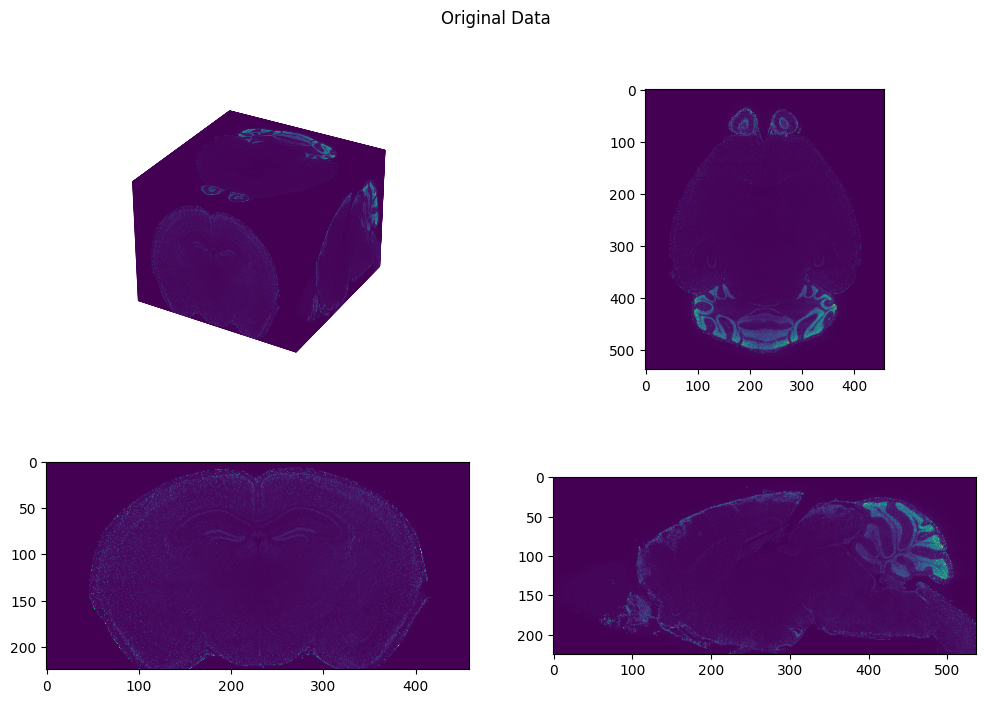

In [38]:
res_factor = 16

m0 = vol_stack.shape[0] // 2
m1 = vol_stack.shape[1] // 2
m2 = vol_stack.shape[2] // 2

img0 = vol_stack[m0, :, :]
img0 = img0[::res_factor,::res_factor]

img1 = vol_stack[:, m1, :]
img1 = img1[::res_factor,::res_factor]
img1_3dplot = np.rot90(img1, k=3) # Rotate img1 by 270 degrees, needed to put img1 in the correct orientation in the 3D plot

img2 = vol_stack[:, :, m2]
img2 = img2[::res_factor,::res_factor]
img2_3dplot = np.flip(img2, axis = 0) # Flip img2 along vertical axis, needed to put img2 in the correct orientation in the 3D plot

xmin, ymin, zmin = 0, 0, 0
xmax, ymax, zmax = img0.shape[1], img0.shape[0], img2.shape[0]

fig = plt.figure()
fig.suptitle("Original Data")

ax00 = fig.add_subplot(221, projection = '3d')

ax00.set_xticks([])
ax00.set_yticks([])
ax00.set_zticks([])

# Plot images along outside of cube
imshow3d(ax00, img0, pos = zmax)
imshow3d(ax00, img1_3dplot, value_direction = 'y', pos = 0)
imshow3d(ax00, img2_3dplot, value_direction = 'x', pos = xmax)

# Plot images at midpoint of each ax
# NOTE: In 3D, matplotlib renders images based on relative position, and NOT based on plotting order
# imshow3d(ax00, img0, value_direction = 'z', pos = zmax // 2)
# imshow3d(ax00, img1, value_direction = 'y', pos = ymax // 2, cmap = 'plasma')
# imshow3d(ax00, img2, value_direction = 'x', pos = xmax // 2, cmap = 'inferno')

# Use a Poly3D Collection for visualization
# collection = TODO
# ax00.add_collection(collection)

ax00.set_xlim([0,xmax])
ax00.set_ylim([0,ymax])
ax00.set_zlim([0,zmax])


ax01 = fig.add_subplot(222)
ax01.imshow(img0)

ax10 = fig.add_subplot(223)
ax10.imshow(img1)

ax11 = fig.add_subplot(224)
ax11.imshow(img2)


fig.set_size_inches(12,8)


## (0.2) Preprocessed Input

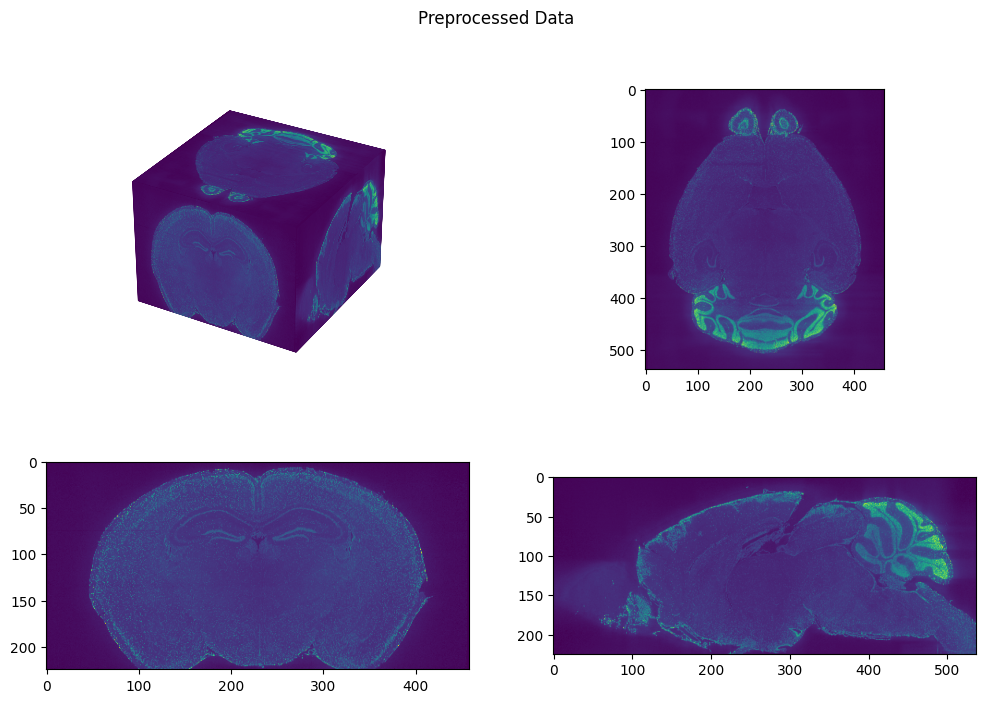

In [41]:
res_factor = 32

m0 = vol_stack.shape[0] // 2
m1 = vol_stack.shape[1] // 2
m2 = vol_stack.shape[2] // 2


img0 = preprocess(vol_stack[m0, :, :])
img0 = img0[::res_factor,::res_factor]

img1 = preprocess(vol_stack[:, m1, :])
img1 = img1[::res_factor,::res_factor]
img1_3dplot = np.rot90(img1, k=3) # Rotate img1 by 270 degrees, needed to put img1 in the correct orientation in the 3D plot

img2 = preprocess(vol_stack[:, :, m2])
img2 = img2[::res_factor,::res_factor]
img2_3dplot = np.flip(img2, axis = 0) # Flip img2 along vertical axis, needed to put img2 in the correct orientation in the 3D plot


xmin, ymin, zmin = 0, 0, 0
xmax, ymax, zmax = img0.shape[1], img0.shape[0], img2.shape[0]

fig = plt.figure()
fig.suptitle("Preprocessed Data")

ax00 = fig.add_subplot(221, projection = '3d')

ax00.set_xticks([])
ax00.set_yticks([])
ax00.set_zticks([])

# Plot images along outside of cube
imshow3d(ax00, img0, pos = zmax)
imshow3d(ax00, img1_3dplot, value_direction = 'y', pos = 0)
imshow3d(ax00, img2_3dplot, value_direction = 'x', pos = xmax)

ax00.set_xlim([0,xmax])
ax00.set_ylim([0,ymax])
ax00.set_zlim([0,zmax])

# Plot all 2D slices in separate subplots
ax01 = fig.add_subplot(222)
ax01.imshow(img0)

ax10 = fig.add_subplot(223)
ax10.imshow(img1)

ax11 = fig.add_subplot(224)
ax11.imshow(img2)


fig.set_size_inches(12,8)

## (0.3) 3 stacks of 2D slices

In [84]:
# Initialize stack of 'num_slices' parallel slices along each ax
num_slices = 10
slice_idx0 = np.arange(0, vol_stack.shape[0], vol_stack.shape[0]/num_slices)
slice_idx1 = np.arange(0, vol_stack.shape[1], vol_stack.shape[1]/num_slices)
slice_idx2 = np.arange(0, vol_stack.shape[2], vol_stack.shape[2]/num_slices)

res_factor = 16

start = time.time()
img0_stack = []
for idx in slice_idx0:
    print(f'Starting {int(idx)} / {vol_stack.shape[0]} . . .')
    img0 = vol_stack[int(idx), :, :]
    img0 = preprocess(img0[::res_factor, ::res_factor], upsample = False)
    img0_stack.append(img0)
print(f'Finished stacking ax0 in {time.time()-start:.2f}s\n')

start = time.time()
img1_stack = []
for idx in slice_idx1:
    print(f'Starting {int(idx)} / {vol_stack.shape[1]} . . .')
    img1 = vol_stack[:, int(idx), :]
    img1 = np.rot90(img1, k=3) # Rotate img1 by 270 degrees, needed to put img1 in the correct orientation in the 3D plot
    img1 = preprocess(img1[::res_factor, ::res_factor], upsample = False)
    img1_stack.append(img1)
print(f'Finished stacking ax1 in {time.time()-start:.2f}s\n')

start = time.time()
img2_stack = []
for idx in slice_idx2:
    print(f'Starting {int(idx)} / {vol_stack.shape[2]} . . .')
    img2 = vol_stack[:, :, int(idx)]
    img2 = np.flip(img2, axis = 0) # Flip img2 along vertical axis, needed to put img2 in the correct orientation in the 3D plot
    img2 = preprocess(img2[::res_factor, ::res_factor], upsample = False)
    img2_stack.append(img2)
print(f'Finished stacking ax2 in {time.time()-start:.2f}s\n')


Starting 0 / 3600 . . .
Starting 360 / 3600 . . .
Starting 720 / 3600 . . .
Starting 1080 / 3600 . . .
Starting 1440 / 3600 . . .
Starting 1800 / 3600 . . .
Starting 2160 / 3600 . . .
Starting 2520 / 3600 . . .
Starting 2880 / 3600 . . .
Starting 3240 / 3600 . . .
Finished stacking ax0 in 5.69s

Starting 0 / 8587 . . .
Starting 858 / 8587 . . .
Starting 1717 / 8587 . . .
Starting 2576 / 8587 . . .
Starting 3434 / 8587 . . .
Starting 4293 / 8587 . . .
Starting 5152 / 8587 . . .
Starting 6010 / 8587 . . .
Starting 6869 / 8587 . . .
Starting 7728 / 8587 . . .
Finished stacking ax1 in 77.23s

Starting 0 / 7321 . . .
Starting 732 / 7321 . . .
Starting 1464 / 7321 . . .
Starting 2196 / 7321 . . .
Starting 2928 / 7321 . . .
Starting 3660 / 7321 . . .
Starting 4392 / 7321 . . .
Starting 5124 / 7321 . . .
Starting 5856 / 7321 . . .
Starting 6588 / 7321 . . .
Finished stacking ax2 in 4.83s



Finished generating plot in 93.69s


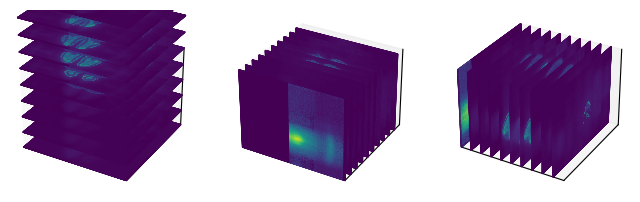

In [85]:
xmin, ymin, zmin = 0, 0, 0
xmax, ymax, zmax = img0.shape[1], img0.shape[0], img2.shape[0]

fig = plt.figure()
# fig.suptitle("Preprocessed Data")

slice_idx0_plot = np.arange(0, img1_stack[0].shape[0], img1_stack[0].shape[0]/num_slices)
slice_idx1_plot = np.arange(0, img0_stack[0].shape[0], img0_stack[0].shape[0]/num_slices)
slice_idx2_plot = np.arange(0, img0_stack[0].shape[1], img0_stack[0].shape[1]/num_slices)

start = time.time()
# Plot stack of slices along ax0
ax0 = fig.add_subplot(131, projection = '3d')
for idx, img0 in enumerate(img0_stack):
    imshow3d(ax0, img0, value_direction = 'z', pos = int(slice_idx0_plot[idx]))

# Plot stack of slices along ax1
ax1 = fig.add_subplot(132, projection = '3d')
for idx, img1 in enumerate(img1_stack):
    imshow3d(ax1, img1, value_direction = 'y', pos = int(slice_idx1_plot[idx]))

# Plot stack of slices along ax2
ax2 = fig.add_subplot(133, projection = '3d')
for idx, img2 in enumerate(img2_stack):
    imshow3d(ax2, img2, value_direction = 'x', pos = int(slice_idx2_plot[idx]))

for ax in [ax0, ax1, ax2]:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])
    
    ax.set_xlim([0,xmax])
    ax.set_ylim([0,ymax])
    ax.set_zlim([0,zmax])

print(f'Finished generating plot in {time.time()-start:.2f}s')

fig.set_size_inches(8,12)

In [83]:
img0_stack[0].shape, img1_stack[0].shape,img2_stack[0].shape

((1074, 916), (916, 450), (450, 1074))

In [81]:
print(slice_idx0_plot)
print(slice_idx1_plot)
print(slice_idx2_plot)


[  0.   91.6 183.2 274.8 366.4 458.  549.6 641.2 732.8 824.4]
[  0.  107.4 214.8 322.2 429.6 537.  644.4 751.8 859.2 966.6]
[  0.   91.6 183.2 274.8 366.4 458.  549.6 641.2 732.8 824.4]
